In [1]:
import os
import pandas as pd
import numpy as np

# Step 1: Automatically find the exact folder path of the Olist dataset
data_path = ""
for dirname, _, filenames in os.walk('/kaggle/input'):
    if 'olist_orders_dataset.csv' in filenames:
        data_path = dirname
        break

print("Dataset folder found at:", data_path)
print("-" * 60)

# Step 2: Load all 9 CSV files into separate DataFrames
orders       = pd.read_csv(f"{data_path}/olist_orders_dataset.csv")
order_items  = pd.read_csv(f"{data_path}/olist_order_items_dataset.csv")
payments     = pd.read_csv(f"{data_path}/olist_order_payments_dataset.csv")
reviews      = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv")
customers    = pd.read_csv(f"{data_path}/olist_customers_dataset.csv")
products     = pd.read_csv(f"{data_path}/olist_products_dataset.csv")
sellers      = pd.read_csv(f"{data_path}/olist_sellers_dataset.csv")
geolocation  = pd.read_csv(f"{data_path}/olist_geolocation_dataset.csv")
cat_trans    = pd.read_csv(f"{data_path}/product_category_name_translation.csv")

# Step 3: Inspect shape (rows, columns) of each table
tables = {
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "customers": customers,
    "products": products,
    "sellers": sellers,
    "geolocation": geolocation,
    "cat_trans": cat_trans
}

for name, df in tables.items():
    print(f"{name:15} -> Rows: {df.shape[0]:,} | Cols: {df.shape[1]}")

Dataset folder found at: /kaggle/input/datasets/olistbr/brazilian-ecommerce
------------------------------------------------------------
orders          -> Rows: 99,441 | Cols: 8
order_items     -> Rows: 112,650 | Cols: 7
payments        -> Rows: 103,886 | Cols: 5
reviews         -> Rows: 99,224 | Cols: 7
customers       -> Rows: 99,441 | Cols: 5
products        -> Rows: 32,951 | Cols: 9
sellers         -> Rows: 3,095 | Cols: 4
geolocation     -> Rows: 1,000,163 | Cols: 5
cat_trans       -> Rows: 71 | Cols: 2


In [2]:
# 1. Check missing values (only showing columns that have nulls)
print("=== MISSING VALUES ===")
for name, df in tables.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if not nulls.empty:
        print(f"\n[{name}]")
        for col, cnt in nulls.items():
            pct = (cnt / len(df)) * 100
            print(f"  - {col}: {cnt:,} ({pct:.2f}%)")

# 2. Check exact duplicate rows in each table
print("\n=== EXACT DUPLICATE ROWS ===")
for name, df in tables.items():
    dups = df.duplicated().sum()
    if dups > 0:
        print(f"  - {name}: {dups:,} duplicates")

# 3. Check order_status distribution & date range
print("\n=== ORDER STATUS BREAKDOWN ===")
print(orders['order_status'].value_counts())

print("\n=== ORDER DATE RANGE ===")
print("Min date:", orders['order_purchase_timestamp'].min())
print("Max date:", orders['order_purchase_timestamp'].max())

=== MISSING VALUES ===

[orders]
  - order_approved_at: 160 (0.16%)
  - order_delivered_carrier_date: 1,783 (1.79%)
  - order_delivered_customer_date: 2,965 (2.98%)

[reviews]
  - review_comment_title: 87,656 (88.34%)
  - review_comment_message: 58,247 (58.70%)

[products]
  - product_category_name: 610 (1.85%)
  - product_name_lenght: 610 (1.85%)
  - product_description_lenght: 610 (1.85%)
  - product_photos_qty: 610 (1.85%)
  - product_weight_g: 2 (0.01%)
  - product_length_cm: 2 (0.01%)
  - product_height_cm: 2 (0.01%)
  - product_width_cm: 2 (0.01%)

=== EXACT DUPLICATE ROWS ===
  - geolocation: 261,831 duplicates

=== ORDER STATUS BREAKDOWN ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

=== ORDER DATE RANGE ===
Min date: 2016-09-04 21:15:19
Max date: 2018-10-17 17:30:18


In [3]:
# 1. Filter to delivered orders only & drop rows missing delivery date
orders_clean = orders[orders['order_status'] == 'delivered'].copy()
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

orders_clean = orders_clean.dropna(subset=['order_delivered_customer_date'])

# 2. Translate product categories to English & fill missing with 'unknown'
products_clean = products.merge(cat_trans, on='product_category_name', how='left')
products_clean['category_english'] = products_clean['product_category_name_english'].fillna('unknown')

# 3. Create item-level clean table (for Product Category analysis later)
items_clean = order_items.merge(
    products_clean[['product_id', 'category_english']], on='product_id', how='left'
)
items_clean['item_total'] = items_clean['price'] + items_clean['freight_value']

# 4. Aggregate order_items to order_id level (avoids duplicate rows on merge)
items_agg = items_clean.groupby('order_id').agg(
    items_count=('order_item_id', 'count'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_order_value=('item_total', 'sum'),
    primary_category=('category_english', 'first')
).reset_index()

# 5. Aggregate payments to order_id level
payments_agg = payments.groupby('order_id').agg(
    payment_value=('payment_value', 'sum'),
    payment_type=('payment_type', 'first'),
    payment_installments=('payment_installments', 'max')
).reset_index()

# 6. Aggregate reviews to order_id level (mean score if multiple reviews exist)
reviews_agg = reviews.groupby('order_id').agg(
    review_score=('review_score', 'mean')
).reset_index()

# 7. Merge everything into a single Master Orders Table (1 row = 1 delivered order)
master_orders = (
    orders_clean
    .merge(customers[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
    .merge(items_agg, on='order_id', how='inner')
    .merge(payments_agg, on='order_id', how='left')
    .merge(reviews_agg, on='order_id', how='left')
)

# 8. Feature Engineering (Date & Delivery KPIs)
master_orders['order_year_month'] = master_orders['order_purchase_timestamp'].dt.to_period('M').astype(str)
master_orders['delivery_days'] = (master_orders['order_delivered_customer_date'] - master_orders['order_purchase_timestamp']).dt.days
master_orders['delay_days'] = (master_orders['order_delivered_customer_date'] - master_orders['order_estimated_delivery_date']).dt.days
master_orders['is_late'] = (master_orders['delay_days'] > 0).astype(int)

# 9. Quick sanity check
print(f"Master Orders Shape: {master_orders.shape[0]:,} rows x {master_orders.shape[1]} cols")
print(f"Unique Orders:       {master_orders['order_id'].nunique():,}")
print(f"Unique Customers:    {master_orders['customer_unique_id'].nunique():,}")
print(f"Total Revenue (BRL): {master_orders['total_order_value'].sum():,.2f}")
print(f"Avg Order Value:     {master_orders['total_order_value'].mean():,.2f}")
print(f"Late Delivery %:     {master_orders['is_late'].mean()*100:.2f}%")
print(f"Avg Review Score:    {master_orders['review_score'].mean():.2f}")

Master Orders Shape: 96,470 rows x 24 cols
Unique Orders:       96,470
Unique Customers:    93,350
Total Revenue (BRL): 15,418,394.83
Avg Order Value:     159.83
Late Delivery %:     6.77%
Avg Review Score:    4.16


In [4]:
# 1. Save cleaned tables to Kaggle's cloud working directory (zero laptop storage)
master_orders.to_csv('/kaggle/working/master_orders_clean.csv', index=False)
items_clean.to_csv('/kaggle/working/items_clean.csv', index=False)
print("Saved: master_orders_clean.csv & items_clean.csv in Kaggle Cloud!\n")

# 2. Create a clean Monthly KPI Summary table (ready for Excel for the Web)
monthly_kpi = master_orders.groupby('order_year_month').agg(
    orders=('order_id', 'count'),
    unique_customers=('customer_unique_id', 'nunique'),
    revenue_brl=('total_order_value', 'sum'),
    aov_brl=('total_order_value', 'mean'),
    late_delivery_pct=('is_late', lambda x: x.mean() * 100),
    avg_review=('review_score', 'mean')
).reset_index()

# Round numbers for clean presentation
monthly_kpi['revenue_brl'] = monthly_kpi['revenue_brl'].round(2)
monthly_kpi['aov_brl'] = monthly_kpi['aov_brl'].round(2)
monthly_kpi['late_delivery_pct'] = monthly_kpi['late_delivery_pct'].round(2)
monthly_kpi['avg_review'] = monthly_kpi['avg_review'].round(2)

# Print tab-separated table (easy to copy-paste directly into Excel for the Web)
print(monthly_kpi.to_string(index=False))

Saved: master_orders_clean.csv & items_clean.csv in Kaggle Cloud!

order_year_month  orders  unique_customers  revenue_brl  aov_brl  late_delivery_pct  avg_review
         2016-09       1                 1       143.46   143.46             100.00        1.00
         2016-10     265               262     46490.66   175.44               0.75        4.01
         2016-12       1                 1        19.62    19.62               0.00        5.00
         2017-01     750               718    127482.37   169.98               2.93        4.20
         2017-02    1653              1630    271239.32   164.09               2.96        4.20
         2017-03    2546              2508    414330.95   162.74               4.56        4.19
         2017-04    2303              2274    390812.40   169.70               6.56        4.14
         2017-05    3545              3478    566657.40   159.85               2.99        4.24
         2017-06    3135              3076    490050.37   156.32     

In [5]:
import sqlite3

# 1. Create an in-memory SQL database & load our clean DataFrames as SQL tables
conn = sqlite3.connect(':memory:')
master_orders.to_sql('master_orders', conn, index=False, if_exists='replace')
items_clean.to_sql('items_clean', conn, index=False, if_exists='replace')

# 2. SQL Query 1: Monthly Revenue Trend & MoM Growth % (using CTE + LAG Window Function)
# Note: Filtering from 2017-01 onwards because 2016 had incomplete ramp-up data
query_1 = """
WITH monthly_sales AS (
    SELECT 
        order_year_month,
        COUNT(order_id) AS total_orders,
        ROUND(SUM(total_order_value), 2) AS revenue
    FROM master_orders
    WHERE order_year_month >= '2017-01'
    GROUP BY order_year_month
)
SELECT 
    order_year_month,
    total_orders,
    revenue,
    LAG(revenue) OVER (ORDER BY order_year_month) AS prev_month_revenue,
    ROUND(
        (revenue - LAG(revenue) OVER (ORDER BY order_year_month)) * 100.0 / 
        LAG(revenue) OVER (ORDER BY order_year_month), 
        2
    ) AS mom_growth_pct
FROM monthly_sales
ORDER BY order_year_month;
"""

q1_result = pd.read_sql_query(query_1, conn)
print(q1_result.to_string(index=False))

order_year_month  total_orders    revenue  prev_month_revenue  mom_growth_pct
         2017-01           750  127482.37                 NaN             NaN
         2017-02          1653  271239.32           127482.37          112.77
         2017-03          2546  414330.95           271239.32           52.75
         2017-04          2303  390812.40           414330.95           -5.68
         2017-05          3545  566657.40           390812.40           44.99
         2017-06          3135  490050.37           566657.40          -13.52
         2017-07          3872  566299.08           490050.37           15.56
         2017-08          4193  645832.36           566299.08           14.04
         2017-09          4150  701077.49           645832.36            8.55
         2017-10          4478  751117.01           701077.49            7.14
         2017-11          7288 1153229.37           751117.01           53.54
         2017-12          5513  843078.29          1153229.37   

In [6]:
# Query 2A: Top 10 Product Categories by Revenue & % Share (JOIN + Window Function)
query_2a = """
SELECT 
    i.category_english,
    COUNT(DISTINCT i.order_id) AS total_orders,
    ROUND(SUM(i.item_total), 2) AS revenue,
    ROUND(SUM(i.item_total) * 100.0 / SUM(SUM(i.item_total)) OVER (), 2) AS revenue_share_pct
FROM items_clean i
INNER JOIN master_orders m ON i.order_id = m.order_id
GROUP BY i.category_english
ORDER BY revenue DESC
LIMIT 10;
"""

# Query 2B: Top 10 States by Revenue, Orders & AOV
query_2b = """
SELECT 
    customer_state,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(total_order_value), 2) AS revenue,
    ROUND(AVG(total_order_value), 2) AS aov,
    ROUND(SUM(total_order_value) * 100.0 / SUM(SUM(total_order_value)) OVER (), 2) AS revenue_share_pct
FROM master_orders
GROUP BY customer_state
ORDER BY revenue DESC
LIMIT 10;
"""

print("=== TOP 10 PRODUCT CATEGORIES ===")
print(pd.read_sql_query(query_2a, conn).to_string(index=False))

print("\n=== TOP 10 CUSTOMER STATES ===")
print(pd.read_sql_query(query_2b, conn).to_string(index=False))

=== TOP 10 PRODUCT CATEGORIES ===
     category_english  total_orders    revenue  revenue_share_pct
        health_beauty          8647 1412089.53               9.16
        watches_gifts          5493 1264016.98               8.20
       bed_bath_table          9272 1225209.26               7.95
       sports_leisure          7529 1118062.91               7.25
computers_accessories          6529 1032603.65               6.70
      furniture_decor          6307  880329.92               5.71
           housewares          5743  758392.25               4.92
           cool_stuff          3559  691680.89               4.49
                 auto          3809  669319.92               4.34
         garden_tools          3448  567145.68               3.68

=== TOP 10 CUSTOMER STATES ===
customer_state  total_orders    revenue    aov  revenue_share_pct
            SP         40494 5768518.23 142.45              37.41
            RJ         12350 2055401.57 166.43              13.33
          

In [7]:
# Query 3A: Repeat Purchase Rate (using CTE + CASE WHEN)
query_3a = """
WITH customer_orders AS (
    SELECT 
        customer_unique_id,
        COUNT(order_id) AS order_count
    FROM master_orders
    GROUP BY customer_unique_id
)
SELECT 
    COUNT(*) AS total_unique_customers,
    SUM(CASE WHEN order_count > 1 THEN 1 ELSE 0 END) AS repeat_customers,
    ROUND(SUM(CASE WHEN order_count > 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS repeat_rate_pct
FROM customer_orders;
"""

# Query 3B: Late Delivery vs. Review Score Impact
query_3b = """
SELECT 
    CASE WHEN is_late = 1 THEN 'Late Delivery' ELSE 'On-Time Delivery' END AS delivery_status,
    COUNT(order_id) AS total_orders,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(SUM(CASE WHEN review_score = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(order_id), 2) AS one_star_pct
FROM master_orders
WHERE review_score IS NOT NULL
GROUP BY is_late;
"""

# Query 3C: Top 10 Customers by Lifetime Value (LTV) using DENSE_RANK()
query_3c = """
WITH customer_ltv AS (
    SELECT 
        customer_unique_id,
        customer_state,
        COUNT(order_id) AS total_orders,
        ROUND(SUM(total_order_value), 2) AS total_spent
    FROM master_orders
    GROUP BY customer_unique_id, customer_state
)
SELECT 
    DENSE_RANK() OVER (ORDER BY total_spent DESC) AS ltv_rank,
    customer_unique_id,
    customer_state,
    total_orders,
    total_spent
FROM customer_ltv
LIMIT 10;
"""

print("=== REPEAT PURCHASE RATE ===")
print(pd.read_sql_query(query_3a, conn).to_string(index=False))

print("\n=== LATE DELIVERY VS REVIEW SCORE ===")
print(pd.read_sql_query(query_3b, conn).to_string(index=False))

print("\n=== TOP 10 CUSTOMERS BY LTV ===")
print(pd.read_sql_query(query_3c, conn).to_string(index=False))

=== REPEAT PURCHASE RATE ===
 total_unique_customers  repeat_customers  repeat_rate_pct
                  93350              2801              3.0

=== LATE DELIVERY VS REVIEW SCORE ===
 delivery_status  total_orders  avg_review_score  one_star_pct
On-Time Delivery         89443              4.29          6.58
   Late Delivery          6381              2.27         53.69

=== TOP 10 CUSTOMERS BY LTV ===
 ltv_rank               customer_unique_id customer_state  total_orders  total_spent
        1 0a0a92112bd4c708ca5fde585afaa872             RJ             1     13664.08
        2 da122df9eeddfedc1dc1f5349a1a690c             RJ             2      7571.63
        3 763c8b1c9c68a0229c42c9fc6f662b93             ES             1      7274.88
        4 dc4802a71eae9be1dd28f5d788ceb526             MS             1      6929.31
        5 459bef486812aa25204be022145caa62             ES             1      6922.21
        6 ff4159b92c40ebe40454e3e6a7c35ed6             SP             1      6726.

/tmp/ipykernel_17/4278146896.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_cats, x='item_total', y='category_english', palette='viridis', ax=axes[0, 1])
/tmp/ipykernel_17/4278146896.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=late_rev, x='status', y='review_score', palette=['#2A9D8F', '#E76F51'], ax=axes[1, 0])
/tmp/ipykernel_17/4278146896.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pay_dist, x='payment_type', y='percentage', palette='Set2', ax=axes[1, 1])


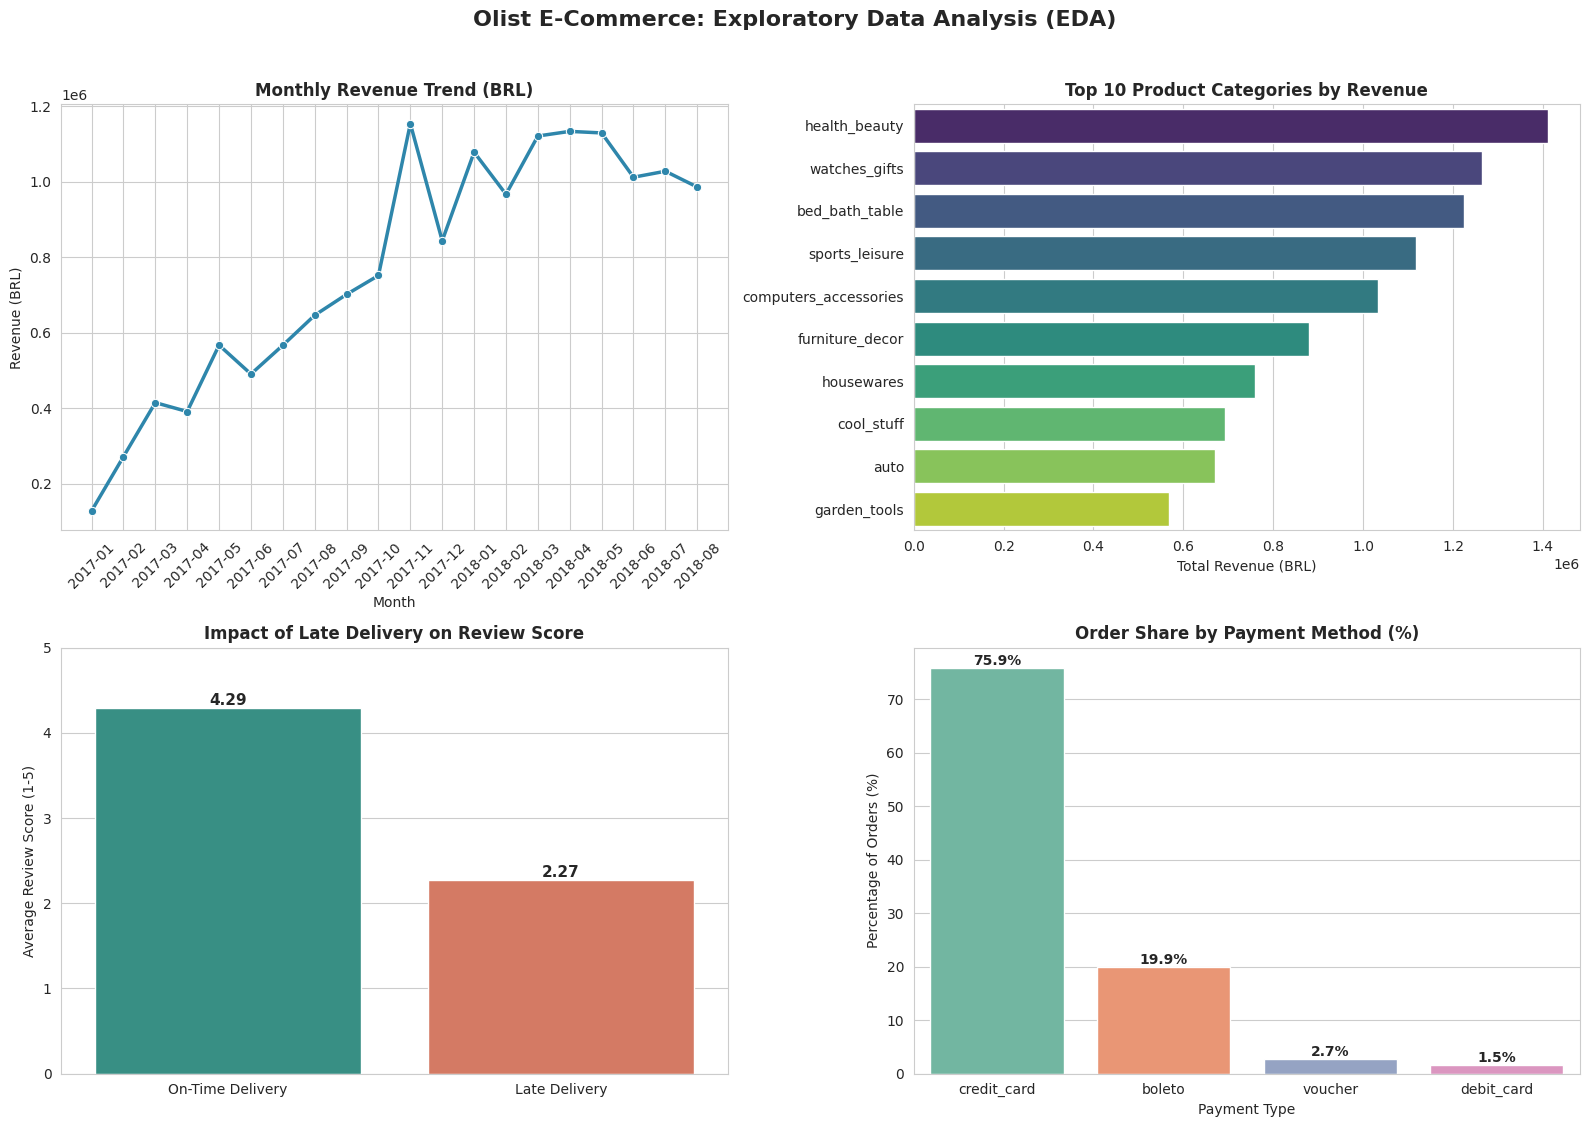

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean professional visual style
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Olist E-Commerce: Exploratory Data Analysis (EDA)', fontsize=16, fontweight='bold', y=1.02)

# --- Chart 1: Monthly Revenue Trend (2017-01 onwards) ---
monthly_rev = (
    master_orders[master_orders['order_year_month'] >= '2017-01']
    .groupby('order_year_month')['total_order_value']
    .sum()
    .reset_index()
)
sns.lineplot(data=monthly_rev, x='order_year_month', y='total_order_value', marker='o', color='#2E86AB', linewidth=2.5, ax=axes[0, 0])
axes[0, 0].set_title('Monthly Revenue Trend (BRL)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Revenue (BRL)')
axes[0, 0].tick_params(axis='x', rotation=45)

# --- Chart 2: Top 10 Product Categories by Revenue ---
top_cats = (
    items_clean[items_clean['order_id'].isin(master_orders['order_id'])]
    .groupby('category_english')['item_total']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
sns.barplot(data=top_cats, x='item_total', y='category_english', palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Top 10 Product Categories by Revenue', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Total Revenue (BRL)')
axes[0, 1].set_ylabel('')

# --- Chart 3: Late Delivery vs. Average Review Score ---
late_rev = master_orders.groupby('is_late')['review_score'].mean().reset_index()
late_rev['status'] = late_rev['is_late'].map({0: 'On-Time Delivery', 1: 'Late Delivery'})
sns.barplot(data=late_rev, x='status', y='review_score', palette=['#2A9D8F', '#E76F51'], ax=axes[1, 0])
axes[1, 0].set_title('Impact of Late Delivery on Review Score', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Average Review Score (1-5)')
axes[1, 0].set_ylim(0, 5)
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2., p.get_height()),
                        ha='center', va='bottom', fontsize=11, fontweight='bold')

# --- Chart 4: Payment Method Distribution (%) ---
pay_dist = master_orders['payment_type'].value_counts(normalize=True).mul(100).reset_index()
pay_dist.columns = ['payment_type', 'percentage']
sns.barplot(data=pay_dist, x='payment_type', y='percentage', palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Order Share by Payment Method (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Payment Type')
axes[1, 1].set_ylabel('Percentage of Orders (%)')
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height()),
                        ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('/kaggle/working/eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# 1. Reference date = 1 day after the last purchase in our dataset
snapshot_date = master_orders['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# 2. Calculate Recency, Frequency, Monetary for each unique customer
rfm = master_orders.groupby('customer_unique_id').agg(
    Recency=('order_purchase_timestamp', lambda x: (snapshot_date - x.max()).days),
    Frequency=('order_id', 'count'),
    Monetary=('total_order_value', 'sum')
).reset_index()

# 3. Assign RFM Scores (1 to 5)
# Recency: lower days = better (score 5)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: since 97% customers ordered only once, use rank(method='first') to avoid bin errors
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetary: higher spend = better (score 5)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 4. Map customers into Business Segments
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Recent / New Buyers'
    elif r <= 2 and m >= 4:
        return 'At-Risk High Value'
    elif r <= 2 and f <= 2:
        return 'Hibernating / Lost'
    else:
        return 'Potential / Average'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# 5. Summary Table by Segment
rfm_summary = rfm.groupby('Segment').agg(
    customers=('customer_unique_id', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean'),
    total_revenue=('Monetary', 'sum')
).reset_index()

rfm_summary['customer_pct'] = (rfm_summary['customers'] / rfm_summary['customers'].sum() * 100).round(2)
rfm_summary['revenue_pct'] = (rfm_summary['total_revenue'] / rfm_summary['total_revenue'].sum() * 100).round(2)
rfm_summary = rfm_summary.sort_values('total_revenue', ascending=False)

# Save RFM table to Kaggle Cloud (for Power BI dashboard later)
rfm.to_csv('/kaggle/working/rfm_customers.csv', index=False)

print("=== RFM SEGMENTATION SUMMARY ===")
print(rfm_summary[['Segment', 'customers', 'customer_pct', 'avg_recency', 'avg_monetary', 'revenue_pct']].round(2).to_string(index=False))

=== RFM SEGMENTATION SUMMARY ===
            Segment  customers  customer_pct  avg_recency  avg_monetary  revenue_pct
 At-Risk High Value      14483         15.51       393.46        310.29        29.15
    Loyal Customers      27284         29.23       144.23        133.96        23.71
Recent / New Buyers      14980         16.05        90.89        163.42        15.88
Potential / Average      20845         22.33       333.66        101.76        13.76
          Champions       6498          6.96        91.12        311.96        13.15
 Hibernating / Lost       9260          9.92       396.34         72.69         4.37


K=2 -> Inertia: 190,197 | Silhouette Score: 0.7103
K=3 -> Inertia: 129,147 | Silhouette Score: 0.4160
K=4 -> Inertia: 82,885 | Silhouette Score: 0.3939
K=5 -> Inertia: 68,308 | Silhouette Score: 0.3527
K=6 -> Inertia: 58,412 | Silhouette Score: 0.3496


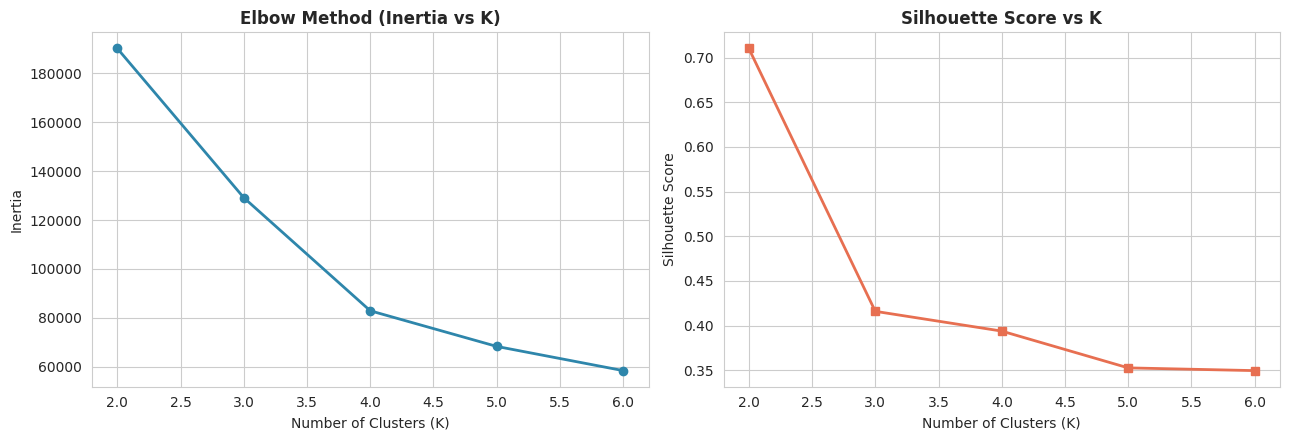


=== K-MEANS CLUSTER SUMMARY (K=4) ===
 Cluster  customers  avg_recency  avg_frequency  avg_monetary
       0      32083       272.89           1.00        296.16
       1       2801       220.29           2.11        308.53
       2      42301       287.41           1.00         68.24
       3      16165        42.24           1.00        133.98


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Log-transform RFM features to handle right-skewness, then scale
rfm_ml = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_ml)

# 2. Find optimal K using Elbow Method (Inertia) & Silhouette Score (k = 2 to 6)
inertias = []
sil_scores = []
K_range = range(2, 7)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    # Using sample_size=10000 so Silhouette Score runs fast on 93K rows
    sil = silhouette_score(rfm_scaled, labels, sample_size=10000, random_state=42)
    sil_scores.append(sil)
    print(f"K={k} -> Inertia: {km.inertia_:,.0f} | Silhouette Score: {sil:.4f}")

# 3. Plot Elbow Curve & Silhouette Score side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(K_range, inertias, marker='o', color='#2E86AB', linewidth=2)
axes[0].set_title('Elbow Method (Inertia vs K)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, sil_scores, marker='s', color='#E76F51', linewidth=2)
axes[1].set_title('Silhouette Score vs K', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.savefig('/kaggle/working/kmeans_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# 4. Fit final K-Means model with K=4 and summarize clusters
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

cluster_summary = rfm.groupby('Cluster').agg(
    customers=('customer_unique_id', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean')
).round(2).reset_index()

# Save updated RFM + Cluster file for Power BI
rfm.to_csv('/kaggle/working/rfm_customers.csv', index=False)

print("\n=== K-MEANS CLUSTER SUMMARY (K=4) ===")
print(cluster_summary.to_string(index=False))

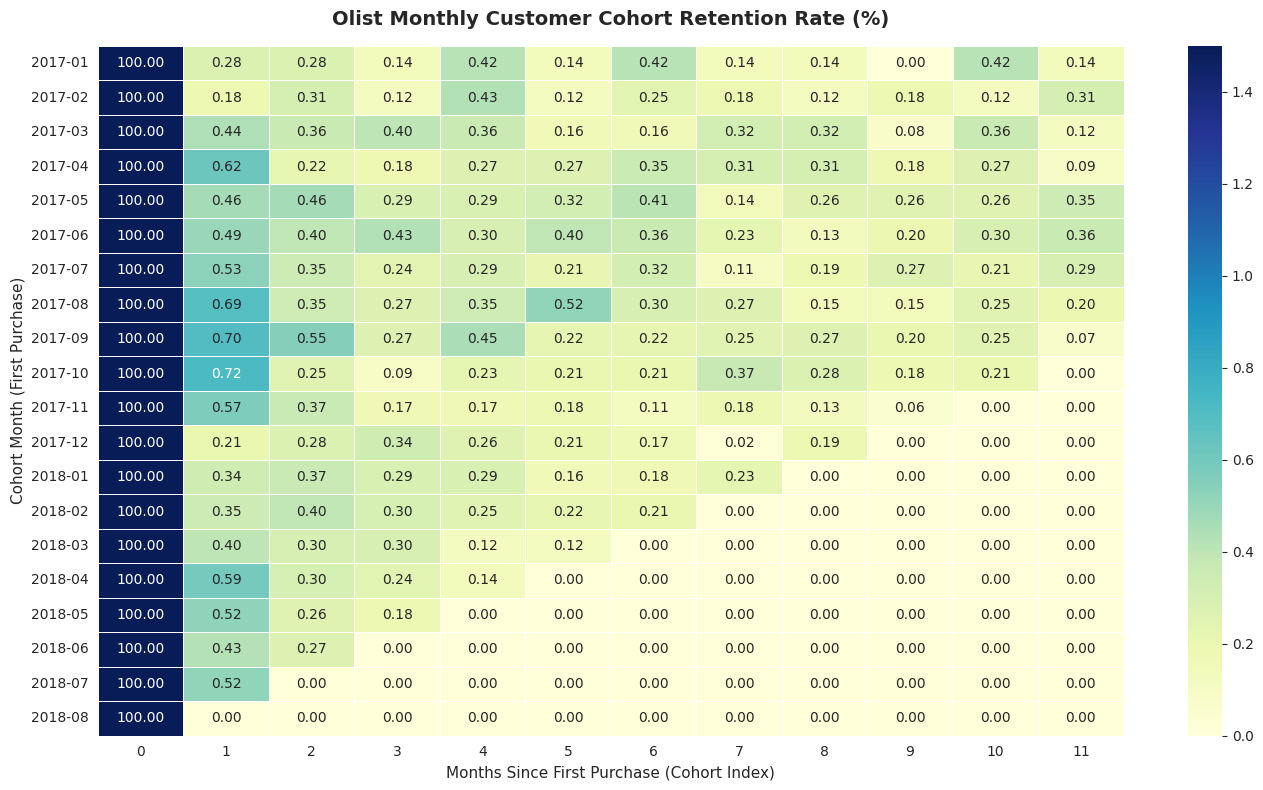

=== AVERAGE RETENTION RATE (AFTER MONTH 0) ===
Month 1: 0.45%
Month 2: 0.30%
Month 3: 0.21%
Month 6: 0.18%


In [11]:
# 1. Filter from 2017-01 onwards for a clean, readable cohort matrix
cohort_df = master_orders[master_orders['order_year_month'] >= '2017-01'][
    ['customer_unique_id', 'order_purchase_timestamp']
].copy()

# 2. Extract Order Month & Customer's First Purchase Month (Cohort Month)
cohort_df['order_month'] = cohort_df['order_purchase_timestamp'].dt.to_period('M')
cohort_df['cohort_month'] = cohort_df.groupby('customer_unique_id')['order_month'].transform('min')

# 3. Calculate Cohort Index (months passed since first purchase: 0, 1, 2, ...)
cohort_df['cohort_index'] = (
    (cohort_df['order_month'].dt.year - cohort_df['cohort_month'].dt.year) * 12 +
    (cohort_df['order_month'].dt.month - cohort_df['cohort_month'].dt.month)
)

# 4. Pivot Table: Count unique customers per Cohort Month & Cohort Index
cohort_counts = cohort_df.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().unstack(fill_value=0)

# 5. Convert counts to Retention Rate (%)
cohort_sizes = cohort_counts.iloc[:, 0]
retention_matrix = cohort_counts.divide(cohort_sizes, axis=0) * 100

# Keep first 12 months (Month 0 to Month 11) for clean visualization
retention_plot = retention_matrix.iloc[:, :12]

# 6. Plot Cohort Retention Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_plot,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=0,
    vmax=1.5,  # Cap color scale at 1.5% so Month 1+ variations are clearly visible
    linewidths=0.5
)
plt.title('Olist Monthly Customer Cohort Retention Rate (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Months Since First Purchase (Cohort Index)', fontsize=11)
plt.ylabel('Cohort Month (First Purchase)', fontsize=11)
plt.tight_layout()
plt.savefig('/kaggle/working/cohort_retention.png', dpi=150, bbox_inches='tight')
plt.show()

# Print average retention for Month 1, Month 2, Month 3
print("=== AVERAGE RETENTION RATE (AFTER MONTH 0) ===")
for m in [1, 2, 3, 6]:
    print(f"Month {m}: {retention_matrix[m].mean():.2f}%")

In [12]:
# 1. Table 1: Monthly KPI Summary (for Page 1: Executive Summary)
t1_monthly = master_orders[master_orders['order_year_month'] >= '2017-01'].groupby('order_year_month').agg(
    Orders=('order_id', 'count'),
    Customers=('customer_unique_id', 'nunique'),
    Revenue=('total_order_value', 'sum'),
    AOV=('total_order_value', 'mean'),
    Late_Orders=('is_late', 'sum'),
    Late_Pct=('is_late', lambda x: x.mean() * 100),
    Avg_Review=('review_score', 'mean')
).round(2).reset_index()

# 2. Table 2: Top 15 Categories (for Page 2: Product Performance)
items_delivered = items_clean.merge(
    master_orders[['order_id', 'review_score', 'is_late']], on='order_id', how='inner'
)
t2_category = items_delivered.groupby('category_english').agg(
    Orders=('order_id', 'count'),
    Revenue=('item_total', 'sum'),
    Avg_Price=('price', 'mean'),
    Late_Pct=('is_late', lambda x: x.mean() * 100),
    Avg_Review=('review_score', 'mean')
).round(2).sort_values('Revenue', ascending=False).head(15).reset_index()

# 3. Table 3: State Performance (for Page 1 & 2 Geo Map)
t3_state = master_orders.groupby('customer_state').agg(
    Orders=('order_id', 'count'),
    Revenue=('total_order_value', 'sum'),
    AOV=('total_order_value', 'mean'),
    Late_Pct=('is_late', lambda x: x.mean() * 100),
    Avg_Review=('review_score', 'mean')
).round(2).sort_values('Revenue', ascending=False).reset_index()

# 4. Table 4: RFM Customer Segments (for Page 3: Customer Insights)
t4_rfm = rfm.groupby('Segment').agg(
    Customers=('customer_unique_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).round(2).sort_values('Total_Revenue', ascending=False).reset_index()

print("--- TABLE 1: MONTHLY ---")
print(t1_monthly.to_csv(index=False))
print("--- TABLE 2: CATEGORY ---")
print(t2_category.to_csv(index=False))
print("--- TABLE 3: STATE ---")
print(t3_state.to_csv(index=False))
print("--- TABLE 4: RFM ---")
print(t4_rfm.to_csv(index=False))

--- TABLE 1: MONTHLY ---
order_year_month,Orders,Customers,Revenue,AOV,Late_Orders,Late_Pct,Avg_Review
2017-01,750,718,127482.37,169.98,22,2.93,4.2
2017-02,1653,1630,271239.32,164.09,49,2.96,4.2
2017-03,2546,2508,414330.95,162.74,116,4.56,4.19
2017-04,2303,2274,390812.4,169.7,151,6.56,4.14
2017-05,3545,3478,566657.4,159.85,106,2.99,4.24
2017-06,3135,3076,490050.37,156.32,95,3.03,4.22
2017-07,3872,3802,566299.08,146.25,108,2.79,4.26
2017-08,4193,4114,645832.36,154.03,122,2.91,4.31
2017-09,4150,4083,701077.49,168.93,182,4.39,4.27
2017-10,4478,4417,751117.01,167.73,187,4.18,4.21
2017-11,7288,7182,1153229.37,158.24,904,12.4,3.99
2017-12,5513,5450,843078.29,152.93,411,7.46,4.09
2018-01,7069,6974,1077887.46,152.48,403,5.7,4.11
2018-02,6555,6400,966168.41,147.39,926,14.13,3.88
2018-03,7003,6914,1120598.24,160.02,1328,18.96,3.81
2018-04,6798,6744,1132878.93,166.65,306,4.5,4.21
2018-05,6749,6693,1128774.52,167.25,443,6.56,4.24
2018-06,6096,6058,1011448.96,165.92,71,1.16,4.31
2018-07,6156,6097,1